<a href="https://colab.research.google.com/github/A-KOStov/Evlash-Valeria-2253/blob/main/kr_task04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

In [ ]:
v0 = 20.0
t = np.linspace(0, 300, 1000)
m_truck = 2000.0
k_truck = 500.0
m_wheel = 25.0
k_wheel = 2.0

In [ ]:
x_truck_analytical = (m_truck * v0 / k_truck) * (1 - np.exp(-(k_truck / m_truck) * t))
x_wheel_analytical = (m_wheel * v0 / k_wheel) * (1 - np.exp(-(k_wheel / m_wheel) * t))

In [ ]:
def system_ode(z, t, m, k):
    x, v = z
    dxdt = v
    dvdt = -(k / m) * v
    return [dxdt, dvdt]

z0 = [0.0, v0]
sol_truck = odeint(system_ode, z0, t, args=(m_truck, k_truck))
sol_wheel = odeint(system_ode, z0, t, args=(m_wheel, k_wheel))

x_truck_numeric = sol_truck[:, 0]
x_wheel_numeric = sol_wheel[:, 0]

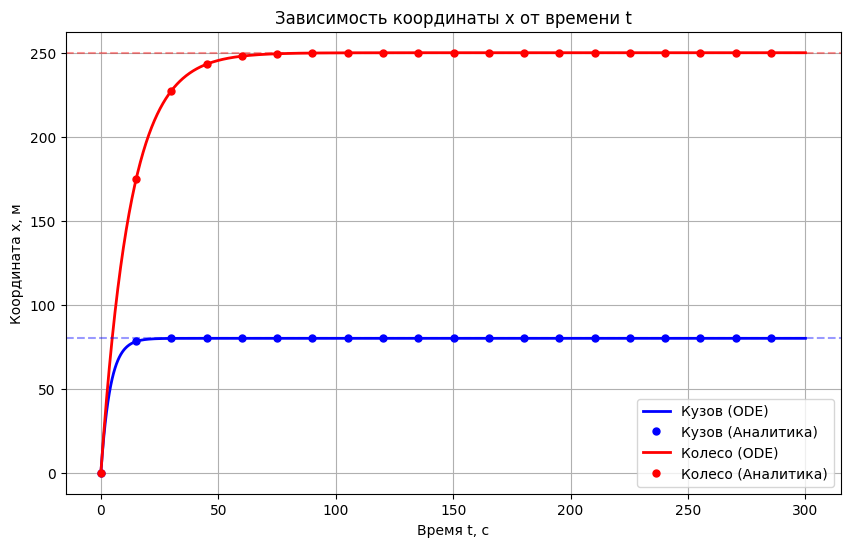

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(t, x_truck_numeric,
         label='Кузов (ODE)',
         color='blue', linewidth=2)

plt.plot(t[::50], x_truck_analytical[::50],
         'bo', label='Кузов (Аналитика)',
         markersize=5)

plt.plot(t, x_wheel_numeric,
         label='Колесо (ODE)',
         color='red', linewidth=2)

plt.plot(t[::50], x_wheel_analytical[::50],
         'ro', label='Колесо (Аналитика)',
         markersize=5)

plt.axhline(y=stop_dist_truck,
            color='blue', linestyle='--', alpha=0.4)

plt.axhline(y=stop_dist_wheel,
            color='red', linestyle='--', alpha=0.4)

plt.title('Зависимость координаты x от времени t')
plt.xlabel('Время t, с')
plt.ylabel('Координата x, м')
plt.grid(True)
plt.legend()
plt.show()

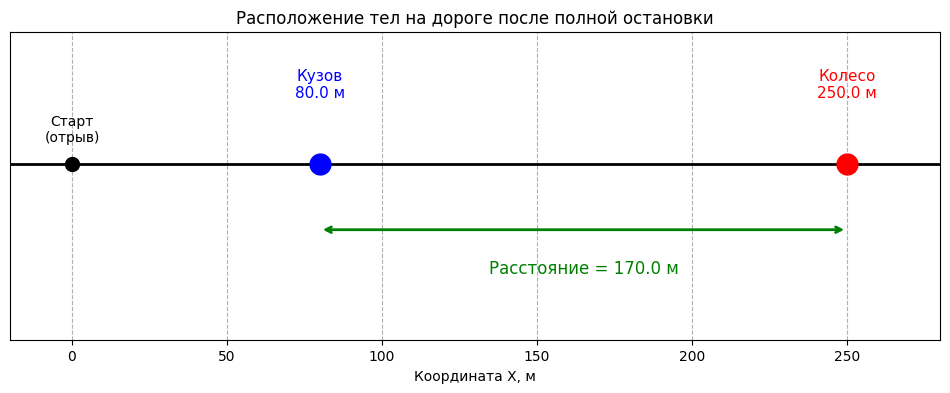

In [ ]:
plt.figure(figsize=(12, 4))

plt.axhline(y=0, color='black', linewidth=2)

plt.plot(0, 0, 'ko', markersize=10)
plt.text(0, 5, 'Старт\n(отрыв)',
         ha='center', fontsize=10)

plt.plot(stop_dist_truck, 0, 'bo', markersize=15)
plt.text(stop_dist_truck, 15,
         f'Кузов\n{stop_dist_truck} м',
         ha='center', color='blue', fontsize=11)

plt.plot(stop_dist_wheel, 0, 'ro', markersize=15)
plt.text(stop_dist_wheel, 15,
         f'Колесо\n{stop_dist_wheel} м',
         ha='center', color='red', fontsize=11)

plt.annotate('', xy=(stop_dist_wheel, -15),
             xytext=(stop_dist_truck, -15),
             arrowprops=dict(arrowstyle='<->',
                             color='green', lw=2))
plt.text((stop_dist_truck + stop_dist_wheel)/2, -25,
         f'Расстояние = {distance:.1f} м',
         ha='center', color='green', fontsize=12)

plt.title('Расположение тел на дороге после полной остановки')
plt.yticks([])
plt.ylim(-40, 30)
plt.xlim(-20, 280)
plt.xlabel('Координата X, м')
plt.grid(axis='x', linestyle='--')

plt.show()